# **Problem Statement**

Develop end-to-end Machine Learning regression system that predicts an nightly rental Air-BnB property in New York City

In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler



## **Displaying the DataFrame**

In [55]:
air_bnb = pd.read_excel("AB_NYC_2019_classroom_30000.xlsx")
display(air_bnb)

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,100000,Entire home/apt in East Village,17749,James,Manhattan,East Village,40.79192,-73.95220,Entire home/apt,393,7,31,2016-10-06,1.45,1,217
1,100001,Entire home/apt in Fordham,27211,James,Bronx,Fordham,40.80563,-73.87973,Entire home/apt,310,4,25,2017-05-10,0.44,1,277
2,100002,Entire home/apt in Greenpoint,19702,Sarah,Brooklyn,Greenpoint,40.64088,-73.88128,Entire home/apt,240,1,29,2017-11-22,1.27,1,207
3,100003,Entire home/apt in Park Slope,39497,Lisa,Brooklyn,Park Slope,40.60449,-73.93313,Entire home/apt,197,1,29,2017-10-27,0.33,1,164
4,100004,Entire home/apt in Upper West Side,7773,Jessica,Manhattan,Upper West Side,40.71641,-73.98910,Entire home/apt,324,3,28,2019-02-28,0.42,1,171
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,129995,Private room in Fordham,14342,David,Bronx,Fordham,40.83925,-73.98873,Private room,45,1,37,2017-02-26,1.01,1,167
29996,129996,Private room in Brooklyn Heights,9804,Chris,Brooklyn,Brooklyn Heights,40.68524,-73.93364,Private room,146,1,34,2017-02-05,1.19,20,217
29997,129997,Private room in Harlem,14462,James,Manhattan,Harlem,40.68470,-74.01788,Private room,196,1,28,2018-02-15,0.51,1,221
29998,129998,Entire home/apt in Upper West Side,58227,Daniel,Manhattan,Upper West Side,40.81049,-73.92540,Entire home/apt,283,1,32,2017-08-21,0.33,1,99


In [56]:
air_bnb.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,100000,Entire home/apt in East Village,17749,James,Manhattan,East Village,40.79192,-73.95220,Entire home/apt,393,7,31,2016-10-06,1.45,1,217
1,100001,Entire home/apt in Fordham,27211,James,Bronx,Fordham,40.80563,-73.87973,Entire home/apt,310,4,25,2017-05-10,0.44,1,277
2,100002,Entire home/apt in Greenpoint,19702,Sarah,Brooklyn,Greenpoint,40.64088,-73.88128,Entire home/apt,240,1,29,2017-11-22,1.27,1,207
3,100003,Entire home/apt in Park Slope,39497,Lisa,Brooklyn,Park Slope,40.60449,-73.93313,Entire home/apt,197,1,29,2017-10-27,0.33,1,164
4,100004,Entire home/apt in Upper West Side,7773,Jessica,Manhattan,Upper West Side,40.71641,-73.98910,Entire home/apt,324,3,28,2019-02-28,0.42,1,171


# **Data Description**


**id:** Data entry index, starting at 100000

**name:** Description of the rental room

**host_id:** ID of the host/owner

**host_name:** Name of the host

**neighbourhood_group:** Borough Location of rental

**neighbourhood:** Neighbourhood location of rental

**latitude:** Horizontal Coordinate

**longitude:** Vertical Corrdinate

**room_type:** Type of rental

**price:** Cost of rental

**minimum_nights:** Duration of stay

**number_of_reviews:** Total reviews of the rental

**last_review:** Latest review of the rental

**reviews_per_month:** Number of reviews on the rental per month

**calculated_host_listings_count:** Number of rentals a host owns

**availability_365:** Number of days rental is available in one year

In [57]:
air_bnb.shape

(30000, 16)

There are **30,000 rows** and **16 columns** on the current DataFrame

In [58]:
air_bnb.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   id                              30000 non-null  int64         
 1   name                            29992 non-null  object        
 2   host_id                         30000 non-null  int64         
 3   host_name                       29988 non-null  object        
 4   neighbourhood_group             30000 non-null  object        
 5   neighbourhood                   30000 non-null  object        
 6   latitude                        30000 non-null  float64       
 7   longitude                       30000 non-null  float64       
 8   room_type                       30000 non-null  object        
 9   price                           30000 non-null  int64         
 10  minimum_nights                  30000 non-null  int64         
 11  nu

In [59]:
air_bnb.isna().sum()

,0
id,0
name,8
host_id,0
host_name,12
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


# **Null Value Observations and Inferences**

In *name* column, 29992 names are non-null

In *host_name* column, 29988 names are non-null

Hence, 8 *name* are **NULL** and 12 *host_name* are also, **NULL**

However, it is also important to observe that the value of *name* and *host_name* doesn't effect the price of the rental, as features are the selling point of the property, not the name of the property or its owner. Hence, the addition/removal of null values in *name* and *host_name* has no impact on the final predicted price on our model.

**TLDR: Although NULL values have been detected in the DataFrame, we wont drop the null values in the dataframe, as they don't contribute to the  Air-BnB rental price prediction model**

In [60]:
air_bnb.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
29995,False
29996,False
29997,False
29998,False


In [61]:
air_bnb.duplicated().sum()

np.int64(0)

# **Duplicate Value Observations and Inferences**

No duplicate values exist in our dataframe

In [62]:
air_bnb.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000,30000.000000,30000.000000,30000.000000
mean,114999.500000,30499.829533,40.711028,-73.952032,200.651300,3.141967,34.968800,2017-12-14 03:01:52.320000,0.902823,3.501900,182.132467
min,100000.000000,1001.000000,40.462010,-74.273060,20.000000,1.000000,12.000000,2016-06-11 00:00:00,0.000000,1.000000,0.000000
25%,107499.750000,15625.000000,40.654855,-73.997580,133.000000,1.000000,31.000000,2017-03-15 00:00:00,0.360000,1.000000,120.000000
50%,114999.500000,30467.500000,40.715915,-73.960685,191.000000,2.000000,35.000000,2017-12-17 00:00:00,0.710000,1.000000,182.000000
75%,122499.250000,45313.000000,40.762930,-73.918170,263.000000,3.000000,39.000000,2018-09-14 00:00:00,1.240000,3.000000,245.000000
max,129999.000000,59999.000000,40.948860,-73.612020,540.000000,30.000000,64.000000,2019-06-15 00:00:00,7.080000,50.000000,363.000000
std,8660.398374,17067.658207,0.068907,0.076388,92.424114,4.600621,5.891122,NaN,0.737399,7.562418,81.596375


## **Data Analysis**

# **A. Univariate Analysis**

The simplest form of statistical analysis where data involves only **one variable** at a time.

We shall only focus on the following attributes in the DataFrame to find:

* **Outliers**
* **Patterns**
* **Observations**

1.   *price* (Boxplot and Histogram/KDE)
2.   *minimum_nights* (Box plot)
3.   *room_type* (Count plot)
4.   *neighbourhood_group* (Count plot)
5.   *number_of_reviews* (Histogram/KDE)
6.   *availability_365* (Histogram/KDE)
7.   *reviews_per_month* (Boxplot and Histogram/KDE)








# **1. Price Distribution**


* Are outliers present? : YES
* Lower Bound of Boxplot : -62.0
* Upper Bound of Boxplot: 458.0
* Total Number of Outliers: 66

The boxplot indicates the presence of **potential** **high-value outliers**. The upper outlier boundary is approximately **458**, while the maximum observed price is **540**. The distribution is *positively/right skewed* due to the concentration of higher-priced observations beyond the upper whisker.

Similiarly, the histogram also point towards rental prices being concentrated mainly in the *lower-to-middle* price range, with fewer listings at higher prices. The distribution is positively/right-skewed, indicating the presence of relatively expensive properties. **This is consistent with the potential high-value outliers identified in the boxplot.**

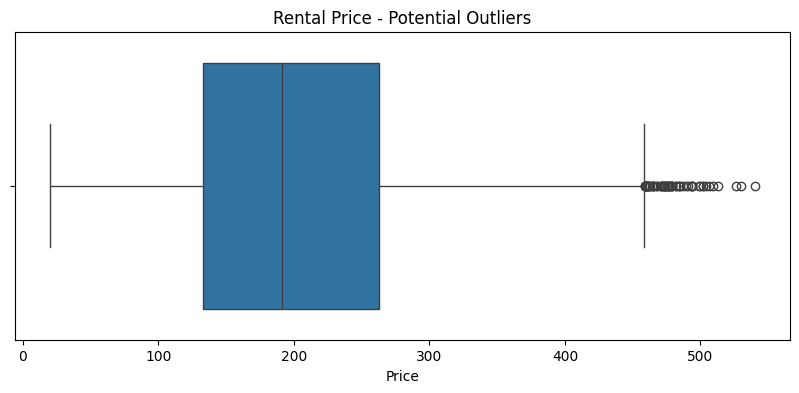

Price quantities: 


,price
0.00,20.0
0.25,133.0
0.50,191.0
0.75,263.0
0.90,333.0
0.99,418.0
1.00,540.0


In [63]:
# Price Boxplot
plt.figure(figsize = (10, 4))
sns.boxplot(x = air_bnb["price"])
plt.title("Rental Price - Potential Outliers")
plt.xlabel("Price")
plt.show()

print("Price quantities: ")
display(air_bnb["price"].quantile([0, 0.25, 0.5, 0.75, 0.9, 0.99, 1]).to_frame("price"))

In [64]:
# Finding Price Outliers
Q1 = air_bnb["price"].quantile(0.25)
Q3 = air_bnb["price"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bound: ", lower_bound)
print("Upper Bound: ", upper_bound)

outliers = air_bnb[
    (air_bnb["price"] < lower_bound) |
    (air_bnb["price"] > upper_bound)
]

print("Number of Outliers: ", len(outliers))


Lower Bound:  -62.0
Upper Bound:  458.0
Number of Outliers:  66


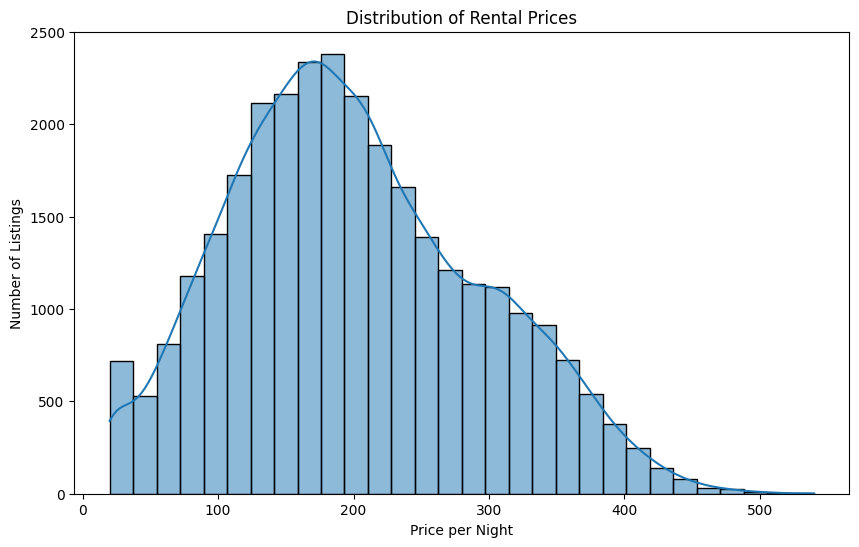

In [65]:
# Price Histogram/KDE
plt.figure(figsize=(10, 6))

sns.histplot(
    air_bnb['price'],
    bins = 30,
    kde = True
)

plt.title('Distribution of Rental Prices')
plt.xlabel('Price per Night')
plt.ylabel('Number of Listings')
plt.show()

# **2. Minimum Nights Distribution**

* The median minimum-night requirement is 2 nights.
* Most listings require a minimum stay of 1 to 3 nights
* A small number of listings have substantially higher minimum-night requirements, reaching up to 30 nights.




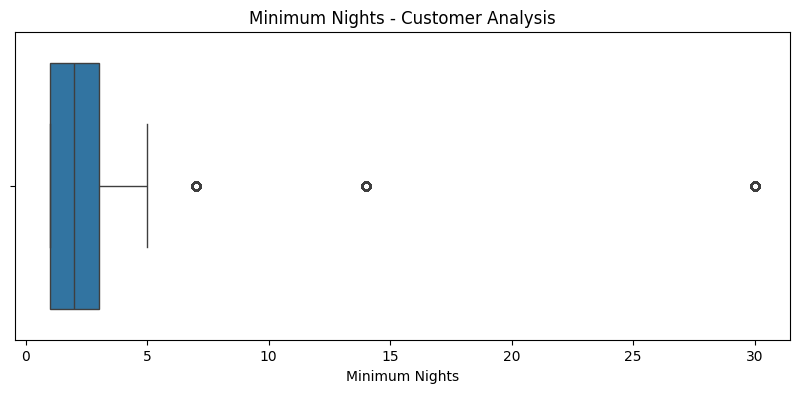

Minimum Nights: 


,minimum_nights
0.00,1.0
0.25,1.0
0.50,2.0
0.75,3.0
0.90,7.0
0.99,30.0
1.00,30.0


In [66]:
# Minimum Nights Boxplot
plt.figure(figsize = (10, 4))
sns.boxplot(x = air_bnb["minimum_nights"])
plt.title("Minimum Nights - Customer Analysis")
plt.xlabel("Minimum Nights")
plt.show()

print("Minimum Nights: ")
display(air_bnb["minimum_nights"].quantile([0, 0.25, 0.5, 0.75, 0.9, 0.99, 1]).to_frame("minimum_nights"))

# **3. Room Type Distribution**

* Most common room type : *Entire home/apt*(15584 listings), approx. **51.95%**
* Least common room type : *Shared room* **(626 listings)** , approx. **2.09%**
* *Private room* is nearly as common **(13790 listings)**, accounting for approx. **45.97%** of the total. Combined, the top two categories represent **97.92%** of the dataset.
* *Shared room* represents a tiny fraction of the dataset at just **2.09%**
* Therefore, the dataset is not evenly distributed across different rental types.

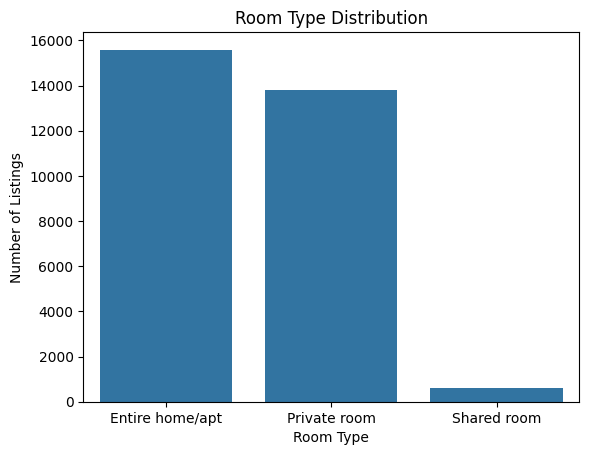

,room_type
room_type,
Entire home/apt,15584
Private room,13790
Shared room,626


In [67]:
# Room type Countplot
sns.countplot(
    data = air_bnb,
    x = "room_type"
)

plt.title("Room Type Distribution")
plt.xlabel("Room Type")
plt.ylabel("Number of Listings")
plt.show()

target_counts = air_bnb["room_type"].value_counts()
display(target_counts.to_frame("room_type"))



# **4. Distribution by Borough/Neighbourhood Group**

* *Manhattan*(**13233** listings) and *Brooklyn*(**12308** listings) dominate the dataset, accounting for **44.11%** and **41.03%** respectively. Combined, they represent over **85.14%** of all listings.

* *Queens* with **2659** listings holds a moderate share at **8.86%**, sitting well behind the top two but significantly ahead of the remaining boroughs.

* The *Bronx* (1208 listings) and *Staten Island* (592 listings) comprise a small minority of the overall listings, accounting for only **4.03%** and **1.97%** respectively. Combined, they contribute only **5.76%** of all listings


The data is geographically unbalanced, with **Manhattan** and **Brooklyn** dominating the listings, meanwhile the **Bronx** and **Staten Island** comprise a small minority. Hence, some boroughs are underrepresented in the listings.

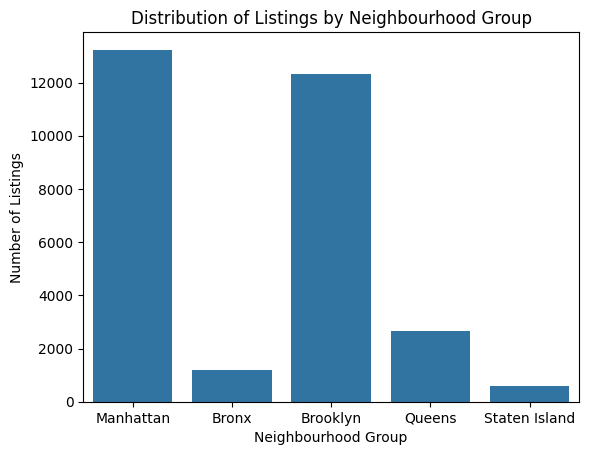

,neighbourhood_group
neighbourhood_group,
Manhattan,13233
Brooklyn,12308
Queens,2659
Bronx,1208
Staten Island,592


In [68]:
# Neighbourhood Group Countplot
sns.countplot(
    data = air_bnb,
    x = "neighbourhood_group"
)

plt.title("Distribution of Listings by Neighbourhood Group")
plt.xlabel("Neighbourhood Group")
plt.ylabel("Number of Listings")
plt.show()

target_counts = air_bnb["neighbourhood_group"].value_counts()
display(target_counts.to_frame("neighbourhood_group"))

## **5. Review Distribution**

* The distribution of the number of reviews is approximately **normal (bell-shaped) and roughly symmetric**, with the Kernel Density Estimate (KDE) curve closely mirroring a **Normal distribution curve**.

* The peak frequency is approx. 34.98 (since **mean** is **34.968800** and **median(50%)** is **35**)

* The highest individual bin counts reach close to **4,000 listings** in the **33–35 review range**.(Each bin count covers approx **1.67** number of reviews)

* The vast majority of listings fall between approximately **20** and **50** reviews(according to the bell-shaped curve observed in the KDE graph). The overall range spans from a minimum of **12** up to a maximum of **64** reviews.

* There are no extreme outliers or heavy long-tail distributions visible, indicating that listings have a tightly bound range of review activity.


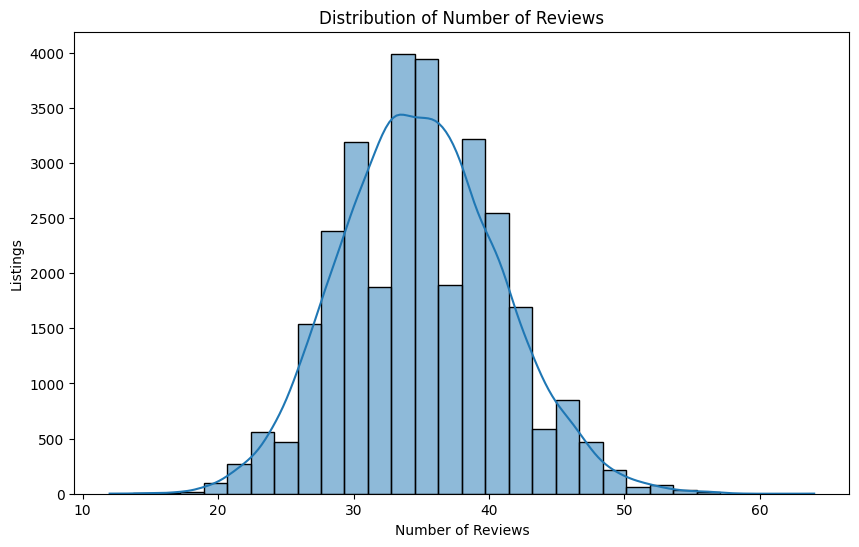

In [69]:
# Number of Reviews Histogram/KDE
plt.figure(figsize=(10, 6))

sns.histplot(
    air_bnb['number_of_reviews'],
    bins = 30,
    kde = True
)

plt.title('Distribution of Number of Reviews')
plt.xlabel('Number of Reviews')
plt.ylabel('Listings')
plt.show()

In [70]:
air_bnb["number_of_reviews"].describe() # Description of number_of_reviews

,number_of_reviews
count,30000.000000
mean,34.968800
std,5.891122
min,12.000000
25%,31.000000
50%,35.000000
75%,39.000000
max,64.000000


## **6. Annual Availability Distribution**

* The distribution of availability is approximately **normal (bell-shaped/dome-shaped) and roughly symmetric**, with the *Kernel Density Estimate (KDE) curve* closely mirroring a **Normal distribution curve**.

* The peak frequency is approx. 182.07 (since **mean** is **182.132467** and **median(50%)** is **182.000000**)

* The highest individual bin counts reach close to **1,500 listings** in the **120–245 review range**.(Each bin count covers approx **10** days)

* The vast majority of listings fall between approximately **120** and **245** days(according to the bell-shaped curve observed in the KDE graph). The overall range spans from a minimum of **0** up to a maximum of **363** days.

* There are no extreme outliers or heavy long-tail distributions visible, indicating that listings have a tightly bound range of annual availability.

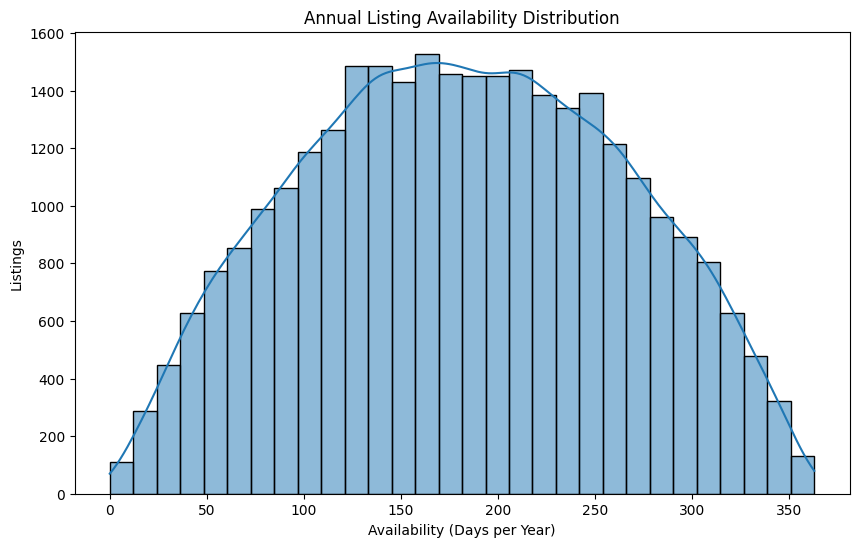

In [71]:
# Availability Histogram/KDE
plt.figure(figsize=(10, 6))

sns.histplot(
    air_bnb['availability_365'],
    bins = 30,
    kde = True
)

plt.title('Annual Listing Availability Distribution')
plt.xlabel('Availability (Days per Year)')
plt.ylabel('Listings')
plt.show()

In [72]:
air_bnb["availability_365"].describe() # Description of availability_365

,availability_365
count,30000.000000
mean,182.132467
std,81.596375
min,0.000000
25%,120.000000
50%,182.000000
75%,245.000000
max,363.000000


### **7. Reviews per Month Distribution**

* Are outliers present? : YES
* Lower Bound of Boxplot : -0.96
* Upper Bound of Boxplot: 2.56
* Total Number of Outliers: 1109

The boxplot indicates the presence of **potential high-value outliers**. The upper outlier boundary is approximately **2.56**, while the maximum observed reviews per month is **7.08**. The distribution is* positively/right skewed* due to the concentration of higher review frequency observations beyond the upper whisker.

Similarly, the histogram also points towards reviews per month being concentrated mainly in the lower range, with fewer listings at higher frequencies. The distribution is *positively/right-skewed*, indicating the presence of properties with relatively high review frequencies. **This is consistent with the potential high-value outliers identified in the boxplot.**

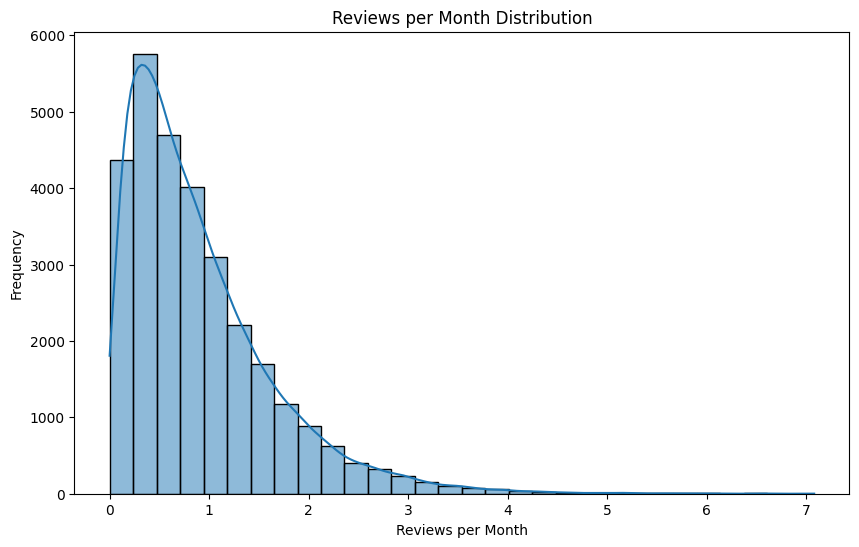

In [73]:
# Reviews Per Month Histogram/KDE
plt.figure(figsize=(10, 6))

sns.histplot(
    air_bnb['reviews_per_month'],
    bins = 30,
    kde = True
)

plt.title('Reviews per Month Distribution')
plt.xlabel('Reviews per Month')
plt.ylabel('Frequency')
plt.show()

In [74]:
air_bnb["reviews_per_month"].describe() # Description of reviews_per_month

,reviews_per_month
count,30000.000000
mean,0.902823
std,0.737399
min,0.000000
25%,0.360000
50%,0.710000
75%,1.240000
max,7.080000


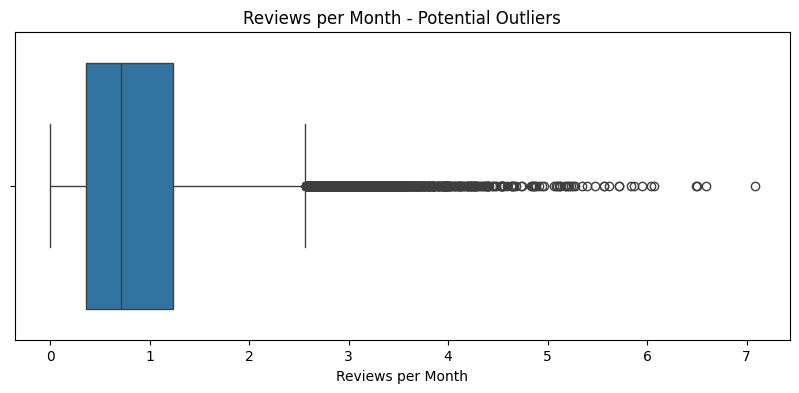

Price quantities: 


,reviews_per_month
0.00,0.00
0.25,0.36
0.50,0.71
0.75,1.24
0.90,1.88
0.99,3.42
1.00,7.08


In [75]:
# Reviews Per Month Boxplot
plt.figure(figsize = (10, 4))
sns.boxplot(x = air_bnb["reviews_per_month"])
plt.title("Reviews per Month - Potential Outliers")
plt.xlabel("Reviews per Month")
plt.show()

print("Price quantities: ")
display(air_bnb["reviews_per_month"].quantile([0, 0.25, 0.5, 0.75, 0.9, 0.99, 1]).to_frame("reviews_per_month"))

In [76]:
# Finding Reviews per Month Outliers
Q1 = air_bnb["reviews_per_month"].quantile(0.25)
Q3 = air_bnb["reviews_per_month"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bound: ", lower_bound)
print("Upper Bound: ", upper_bound)

outliers = air_bnb[
    (air_bnb["reviews_per_month"] < lower_bound) |
    (air_bnb["reviews_per_month"] > upper_bound)
]

print("Number of Outliers: ", len(outliers))


Lower Bound:  -0.9600000000000001
Upper Bound:  2.56
Number of Outliers:  1109


# **B. Bivariate Analysis**

An analysis involving **two** different variables simultaneously to explore the association, correlation, or causal relationship between them.

We will compare relevent columns in the data set to the *price* column to understand how does that variable affect the price of the rental listing.

1. room_type vs price (Box plot)
2. neighbourhood_group vs price (Box plot)
3. minimum_nights vs price (Scatter plot)
4. number_of_reviews vs price (Scatter plot)
5. availability_365 vs price (Scatter plot)

# **1. *room_type* vs. *price* Comparison**

Here, we compare the **price distribution of different room types** to understand how rental prices vary depending on the type of accommodation.

## Observations

- There are **30,000 total observations** across **3 unique room types**, with **Entire home/apt** being the most frequent category (**15,584 listings**), followed by **Private room** (**13,790 listings**) and **Shared room** (**626 listings**).

- The **overall average rental price** across the dataset is **200.65**, with a standard deviation of **92.42**, ranging from a minimum of **20.00** to a maximum of **540.00**.

- Rental prices vary considerably by room type:
  1. **Entire home/apt** has the highest price distribution, with a **mean of 252.89** and a **median of 249.00**, making it the **most expensive room type**. Prices range from **20.00 to 540.00**.
  2. **Private room** falls in the middle price range, with a **mean of 145.87** and a **median of 144.00**. Prices range from **20.00 to 437.00**.
  3. **Shared room** has the lowest price distribution, with a **mean of 106.90** and a **median of 101.00**, making it the **least expensive room type**. Prices range from **20.00 to 274.00**.

- The **price spread** also differs between room types. Entire home/apt has the largest interquartile range (**317 − 189 = 128**), indicating greater variation in prices. Private rooms have an IQR of **89**, while shared rooms have an IQR of **81.50**.

- The boxplots indicate the presence of **potential high-value outliers**, particularly for **Entire home/apt** and **Private room**, as their maximum prices extend considerably beyond their upper quartiles.

 Overall, the analysis shows a clear price hierarchy: **Entire home/apt > Private room > Shared room**. This suggests that the type of accommodation has a substantial influence on rental price.

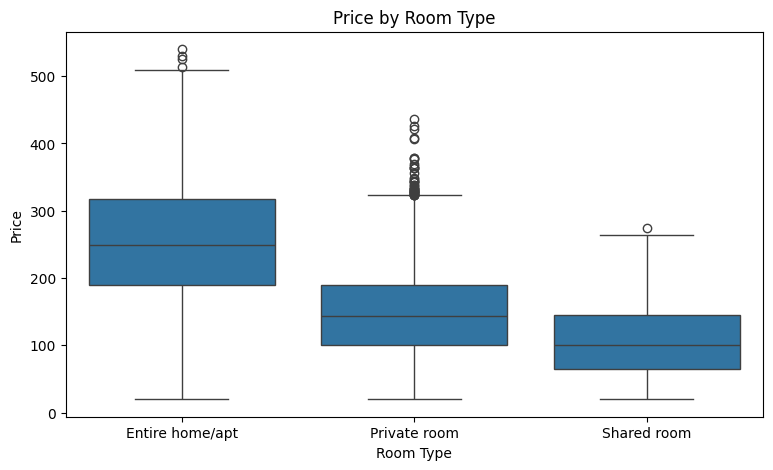

In [77]:
# room_type vs price Comparison
plt.figure(figsize = (9, 5))

sns.boxplot(
    data = air_bnb,
    x = "room_type",
    y = "price"
)

plt.title("Price by Room Type")
plt.xlabel("Room Type")
plt.ylabel("Price")
plt.show()

In [78]:
air_bnb[["room_type", "price"]].describe(include="all") # Description of room_type and price

,room_type,price
count,30000,30000.000000
unique,3,NaN
top,Entire home/apt,NaN
freq,15584,NaN
mean,NaN,200.651300
std,NaN,92.424114
min,NaN,20.000000
25%,NaN,133.000000
50%,NaN,191.000000
75%,NaN,263.000000


In [79]:
air_bnb.groupby("room_type")["price"].describe()

,count,mean,std,min,25%,50%,75%,max
room_type,,,,,,,,
Entire home/apt,15584.0,252.894700,83.562614,20.0,189.00,249.0,317.00,540.0
Private room,13790.0,145.867078,63.744399,20.0,101.00,144.0,190.00,437.0
Shared room,626.0,106.902556,56.461598,20.0,64.25,101.0,145.75,274.0


# **2. *neighbourhood_group* vs *price* Comparison**

Here, we compare the price distribution of different boroughs to understand how rental prices vary geographically.

# Observations
* There are **30,000 total observations** across **5** unique boroughs, with *Manhattan* being the most frequent category with 13,233 listings, followed by Brooklyn with 12,308 listings.
* The overall average rental price across the dataset is **200.65**, with a standard deviation of **92.42**, ranging from a minimum of **20.00** to a maximum of **540.00**.
* Rental prices vary significantly by borough:
    1. *Manhattan* has the highest price distribution, with a mean price of **256.99** and a median of **259.00**, making it the m**ost expensive borough**.
    2. *Brooklyn* has the second-highest prices, with a mean of **161.71** and a median of **162.00**.
    3. *Bronx* and *Queens* have relatively similar price levels. The *Bronx* has a mean of **150.24** and median of **150.00**, while *Queens* has a mean of **144.98** and median of **145.00.**
    4. *Staten Island* has the lowest rental prices, with a mean of **103.87** and a median of **98.50**, making it the **least expensive borough** among the five.
* The maximum observed price is **540.00** in *Manhattan*, while the lowest price of **20.00** occurs *across the dataset*.
* The differences between the medians show a clear geographical variation in rental prices, with *Manhattan* considerably more expensive than the other boroughs, while *Staten Island* occupies the lowest price range.

Overall, *Manhattan* is clearly the most expensive borough, whereas *Staten Island* is the least expensive. *Brooklyn, Bronx, and Queens* fall between these two extremes.

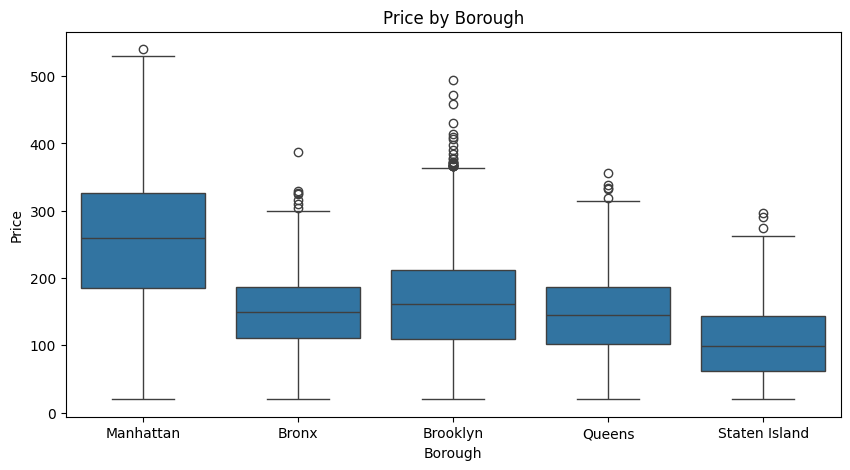

In [80]:
# neighbourhood_group vs price Comparison
plt.figure(figsize = (10, 5))

sns.boxplot(
    data = air_bnb,
    x = "neighbourhood_group",
    y = "price"
)

plt.title("Price by Borough")
plt.xlabel("Borough")
plt.ylabel("Price")
plt.show()

In [81]:
air_bnb[["neighbourhood_group", "price"]].describe(include="all") # Description of neighbourhood_group and price

,neighbourhood_group,price
count,30000,30000.000000
unique,5,NaN
top,Manhattan,NaN
freq,13233,NaN
mean,NaN,200.651300
std,NaN,92.424114
min,NaN,20.000000
25%,NaN,133.000000
50%,NaN,191.000000
75%,NaN,263.000000


In [82]:
air_bnb.groupby("neighbourhood_group")["price"].describe() # Description of price using neightbourhood_group group

,count,mean,std,min,25%,50%,75%,max
neighbourhood_group,,,,,,,,
Bronx,1208.0,150.235099,56.770496,20.0,110.75,150.0,187.25,387.0
Brooklyn,12308.0,161.706289,69.976950,20.0,110.00,162.0,212.00,494.0
Manhattan,13233.0,256.993274,88.044167,20.0,185.00,259.0,326.00,540.0
Queens,2659.0,144.975931,61.536920,20.0,101.50,145.0,187.00,356.0
Staten Island,592.0,103.869932,57.205258,20.0,61.75,98.5,144.25,296.0


# **3. *minimum_nights* vs. *price* Comparison**

Here, we compare the **price distribution based on the minimum number of nights required** to understand whether the minimum stay requirement affects rental prices.

## Observations

- There are **30,000 total observations**. The `minimum_nights` variable has an average of **3.14 nights**, with a standard deviation of **4.60**, ranging from a minimum of **1 night** to a maximum of **30 nights**.

- The overall average rental price across the dataset is **200.65**, with a standard deviation of **92.42**, ranging from a minimum of **20.00** to a maximum of **540.00**.

- Most listings have relatively low minimum-stay requirements. The **median minimum stay is 2 nights**, while the 25th percentile is **1 night** and the 75th percentile is **3 nights**.

- Rental prices remain relatively similar across different minimum-night requirements:
  1. Listings with a **1-night minimum** have a mean price of **200.89** and a median of **191.00**.
  2. Listings with a **2-night minimum** have a mean price of **201.00** and a median of **191.00**.
  3. Listings with a **3-night minimum** have a mean price of **199.21** and a median of **190.00**.
  4. Listings with a **4-night minimum** have the highest mean price at **204.27**, with a median of **195.00**.
  5. Listings with a **5-night minimum** have a mean price of **196.86** and a median of **187.00**.
  6. Listings with a **7-night minimum** have a mean price of **200.97** and a median of **189.00**.
  7. Listings with a **14-night minimum** have a mean price of **199.54** and a median of **191.00**.
  8. Listings with a **30-night minimum** have the lowest mean price among the listed groups at **198.51**, with a median of **180.00**.

- The price range remains wide across all minimum-night categories. Prices generally range from **20.00** to values above **450.00**, indicating considerable variation within each group.

- Overall, there is **no strong or consistent relationship between minimum nights and price**. The average prices remain close to **200** across the different minimum-stay categories.

- The **4-night minimum** category has the highest average price (**204.27**), while the **30-night minimum** category has the lowest average price (**198.51**) among the listed categories.

Therefore, the analysis suggests that **minimum-night requirements have relatively little influence on rental price** in this dataset.

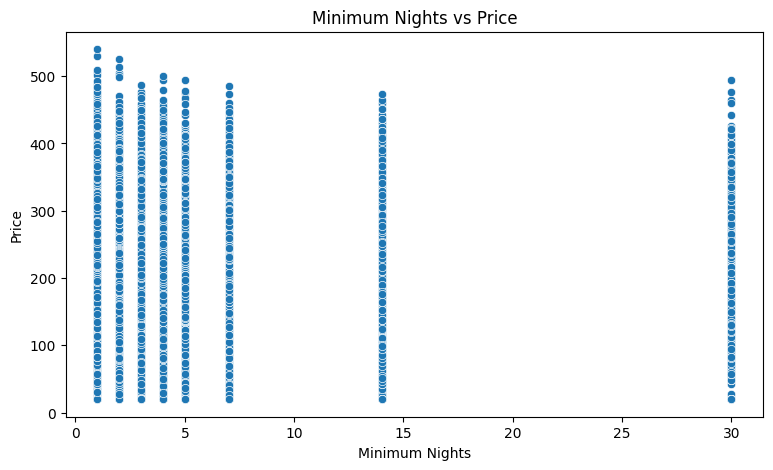

In [83]:
# minimum_nights vs price Comparison
plt.figure(figsize = (9, 5))

sns.scatterplot(
    data = air_bnb,
    x = "minimum_nights",
    y = "price",
)

plt.title("Minimum Nights vs Price")
plt.xlabel("Minimum Nights")
plt.ylabel("Price")
plt.show()

In [84]:
air_bnb[["minimum_nights", "price"]].describe(include="all") # Description of minimum_nights and price

,minimum_nights,price
count,30000.000000,30000.000000
mean,3.141967,200.651300
std,4.600621,92.424114
min,1.000000,20.000000
25%,1.000000,133.000000
50%,2.000000,191.000000
75%,3.000000,263.000000
max,30.000000,540.000000


In [85]:
air_bnb.groupby("minimum_nights")["price"].describe() # Description of price using minimum_nights group

,count,mean,std,min,25%,50%,75%,max
minimum_nights,,,,,,,,
1,14414.0,200.890801,92.456272,20.0,134.00,191.0,263.0,540.0
2,5387.0,201.002970,91.543849,20.0,133.00,191.0,263.0,526.0
3,3039.0,199.206976,92.757211,20.0,130.00,190.0,262.5,487.0
4,2081.0,204.269101,93.415869,20.0,136.00,195.0,270.0,500.0
5,1798.0,196.863737,90.640685,20.0,133.00,187.0,253.0,494.0
7,1810.0,200.965193,93.123778,20.0,134.25,189.0,262.0,485.0
14,885.0,199.535593,96.005951,20.0,127.00,191.0,265.0,473.0
30,586.0,198.506826,92.108562,20.0,132.00,180.0,257.5,494.0


# **4. *number_of_reviews* vs. *price* Comparison**

Here, we compare the **number of reviews** with **rental price** to understand whether listings with more reviews tend to have higher or lower prices.

## Observations

- There are **30,000 total observations** in the dataset. The `number_of_reviews` variable has a mean of **34.97 reviews**, with a standard deviation of **5.89**, ranging from **12 to 64 reviews**.

- The overall average rental price is **200.65**, with a standard deviation of **92.42**, ranging from **20.00 to 540.00**.

- Most listings have between **31 and 39 reviews**, as shown by the 25th percentile of **31** and the 75th percentile of **39**.

- The average price remains relatively stable across most review-count categories. For example:
  1. Listings with **20 reviews** have an average price of **187.39**.
  2. Listings with **25 reviews** have an average price of **207.14**.
  3. Listings with **30 reviews** have an average price of **201.04**.
  4. Listings with **35 reviews** have an average price of **196.08**.
  5. Listings with **40 reviews** have an average price of **203.85**.
  6. Listings with **45 reviews** have an average price of **197.41**.
  7. Listings with **50 reviews** have an average price of **190.93**.

- The highest average price is observed for listings with **52 reviews**, at **222.75**. However, this group contains only **48 listings**, so it should not be considered representative of the entire dataset.

- The largest group is listings with **33 reviews**, containing **2,019 observations**, with an average price of **201.08**.

- The median prices also remain fairly close across most review-count categories. For example, the median price is **191.00** for 30 reviews, **185.00** for 35 reviews, and **195.00** for 40 reviews.

- Price variation within each review-count group is relatively high. For example, listings with **28 reviews** range from **20.00 to 540.00**, while listings with **40 reviews** range from **20.00 to 502.00**.

- Overall, there is **no strong or consistent relationship between the number of reviews and rental price**. Prices fluctuate around the overall average of **200.65** regardless of the number of reviews.

- Therefore, the analysis suggests that **the number of reviews has relatively little influence on rental price** in this dataset. Factors such as **room type and neighbourhood** are likely to have a stronger influence on price.

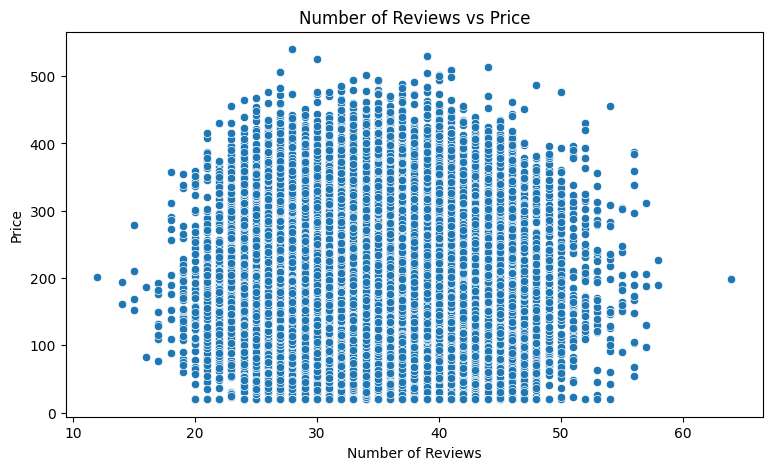

In [86]:
# number_of_reviews vs price Comparison
plt.figure(figsize = (9, 5))

sns.scatterplot(
    data = air_bnb,
    x = "number_of_reviews",
    y = "price",
)

plt.title("Number of Reviews vs Price")
plt.xlabel("Number of Reviews")
plt.ylabel("Price")
plt.show()

In [87]:
air_bnb[["number_of_reviews", "price"]].describe(include="all") # Description of number_of_reviews and price

,number_of_reviews,price
count,30000.000000,30000.000000
mean,34.968800,200.651300
std,5.891122,92.424114
min,12.000000,20.000000
25%,31.000000,133.000000
50%,35.000000,191.000000
75%,39.000000,263.000000
max,64.000000,540.000000


In [88]:
air_bnb.groupby("number_of_reviews")["price"].describe() # Description of price using number_of_reviews group

,count,mean,std,min,25%,50%,75%,max
number_of_reviews,,,,,,,,
12,1.0,201.000000,NaN,201.0,201.00,201.0,201.00,201.0
14,2.0,178.000000,22.627417,162.0,170.00,178.0,186.00,194.0
15,4.0,203.000000,56.261295,153.0,165.00,190.0,228.00,279.0
16,2.0,134.000000,73.539105,82.0,108.00,134.0,160.00,186.0
17,9.0,140.555556,38.072664,77.0,116.00,132.0,176.00,193.0
18,13.0,218.000000,83.948397,88.0,152.00,204.0,287.00,357.0
19,36.0,178.222222,74.370160,60.0,128.75,172.5,214.00,354.0
20,57.0,187.385965,92.834483,20.0,125.00,173.0,255.00,359.0
21,107.0,196.046729,94.064348,20.0,123.50,196.0,247.50,415.0


# **5. *availability_365* vs. *price* Comparison**

Here, we compare the **number of days a listing is available in a year** with its **rental price** to understand whether availability is associated with differences in price.

## Observations

- There are **30,000 total observations**. The `availability_365` variable has a mean of **182.13 days**, with a standard deviation of **81.60**, ranging from **0 to 363 days**.

- The overall average rental price is **200.65**, with a standard deviation of **92.42**, ranging from **20.00 to 540.00**.

- The median availability is **182 days**, while the 25th percentile is **120 days** and the 75th percentile is **245 days**. This indicates that many listings are available for a substantial portion of the year.

- The dataset contains **364 different availability values**, ranging from **0 to 363 days**. However, some availability values have very few listings, so their average prices may not be representative.

- For example, listings with an availability of **2 days** have an average price of **118.00**, while listings with **3 days** have an average price of **249.33**. These groups contain only **5 and 3 listings**, respectively, so they should not be used to draw strong conclusions.

- At higher availability levels, prices continue to vary considerably. For example:
  1. Listings available for **359 days** have an average price of **199.00**.
  2. Listings available for **360 days** have an average price of **166.33**.
  3. Listings available for **361 days** have an average price of **133.80**.
  4. Listings available for **362 days** have an average price of **160.00**.
  5. Listings available for **363 days** have an average price of **171.00**.

- The price variation within individual availability groups is also relatively high. For example, listings available for **359 days** have prices ranging from **53.00 to 318.00**, while listings available for **362 days** range from **61.00 to 259.00**.

Overall, the average prices do not show a clear increasing or decreasing pattern as `availability_365` increases. Prices fluctuate considerably across the different availability levels.Therefore, the analysis suggests that **availability throughout the year does not have a strong or consistent relationship with rental price** in this dataset.

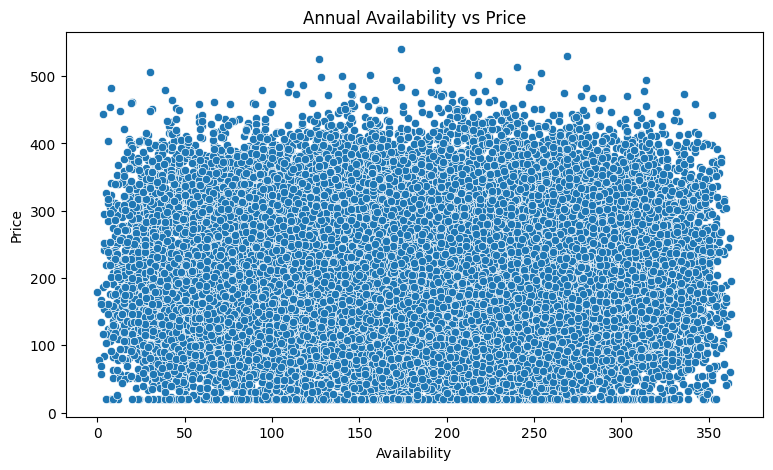

In [89]:
# availability_365 vs price Comparison
plt.figure(figsize = (9, 5))

sns.scatterplot(
    data = air_bnb,
    x = "availability_365",
    y = "price",
)

plt.title("Annual Availability vs Price")
plt.xlabel("Availability")
plt.ylabel("Price")
plt.show()

In [90]:
air_bnb[["availability_365", "price"]].describe(include="all") # Description of availability_365 and price

,availability_365,price
count,30000.000000,30000.000000
mean,182.132467,200.651300
std,81.596375,92.424114
min,0.000000,20.000000
25%,120.000000,133.000000
50%,182.000000,191.000000
75%,245.000000,263.000000
max,363.000000,540.000000


In [91]:
air_bnb.groupby("availability_365")["price"].describe() # Description of price using availability_365 group

,count,mean,std,min,25%,50%,75%,max
availability_365,,,,,,,,
0,1.0,180.000000,NaN,180.0,180.00,180.0,180.0,180.0
1,1.0,78.000000,NaN,78.0,78.00,78.0,78.0,78.0
2,5.0,118.000000,51.332251,58.0,69.00,135.0,161.0,167.0
3,3.0,249.333333,172.181106,117.0,152.00,187.0,315.5,444.0
4,6.0,211.500000,77.505484,84.0,176.00,242.0,249.5,295.0
...,...,...,...,...,...,...,...,...
359,5.0,199.000000,128.625425,53.0,73.00,236.0,315.0,318.0
360,6.0,166.333333,85.635662,41.0,137.25,168.0,184.5,304.0
361,5.0,133.800000,72.867688,44.0,117.00,119.0,143.0,246.0


# **C. Multivariate Analysis**

An advanced statistical approach involving the observation and analysis of three or more variables at the same time.(Here, we will do 3 variables)

1. `price` + `room_type` + `neighbourhood_group` Comparison (Box Plot with Hue)
2. `latitude` + `longitude` + `price` Comparison (Scatter Plot with Hue)
3. `number_of_reviews` + `availability_365` + `price Comparison` (Scatter Plot with Size and Hue)
4. Multiple numerical variables (Correlation Heatmap)

# **1. *Price* by *Neighbourhood Group* and *Room Type***

Here, we analyze **price based on both neighbourhood group and room type** to understand how location and type of accommodation jointly affect rental prices.

## Observations

- The analysis contains **30,000 listings** across **5 neighbourhood groups** and **3 room types**: Entire home/apt, Private room, and Shared room.

- **Entire home/apt** has the highest average price in every neighbourhood group, followed by **Private room** and **Shared room**. This shows that room type has a consistent effect on rental price.

- **Manhattan** has the highest prices across all three room types:
  - **Entire home/apt:** mean price = **325.26**, median = **323.00**
  - **Private room:** mean price = **187.04**, median = **186.00**
  - **Shared room:** mean price = **132.75**, median = **130.50**

- **Brooklyn** has the second-highest prices for all three room types:
  - **Entire home/apt:** mean = **206.34**, median = **206.00**
  - **Private room:** mean = **113.81**, median = **113.00**
  - **Shared room:** mean = **84.46**, median = **77.00**

- **Bronx and Queens** show relatively similar prices:
  - In the Bronx, Entire home/apt has a mean of **175.41**, Private room **125.08**, and Shared room **120.13**.
  - In Queens, Entire home/apt has a mean of **175.99**, Private room **110.73**, and Shared room **84.23**.

- **Staten Island** has the lowest average prices across all room types:
  - **Entire home/apt:** mean = **132.25**, median = **133.00**
  - **Private room:** mean = **75.11**, median = **71.50**
  - **Shared room:** mean = **60.88**, median = **36.50**

- The **most expensive combination** is **Entire home/apt in Manhattan**, with an average price of **325.26** and a median price of **323.00**. Its prices range from **155.00 to 540.00**.

- The **least expensive combination** is **Shared room in Staten Island**, with an average price of **60.88** and a median price of **36.50**.

- The price ranges also show considerable variation within several neighbourhood-room-type combinations. For example, **Manhattan Entire home/apt** ranges from **155.00 to 540.00**, while **Brooklyn Entire home/apt** ranges from **20.00 to 494.00**.

- The results clearly show that **both neighbourhood and room type influence rental price**. Manhattan listings are substantially more expensive than listings in the other neighbourhood groups, while Entire home/apt listings are consistently more expensive than Private room and Shared room listings.

## Conclusion

Overall, the analysis indicates that **location and room type jointly have a strong influence on rental price**. The highest prices are concentrated in **Manhattan**, particularly for **Entire home/apt**, while **Staten Island Shared rooms** have the lowest prices.

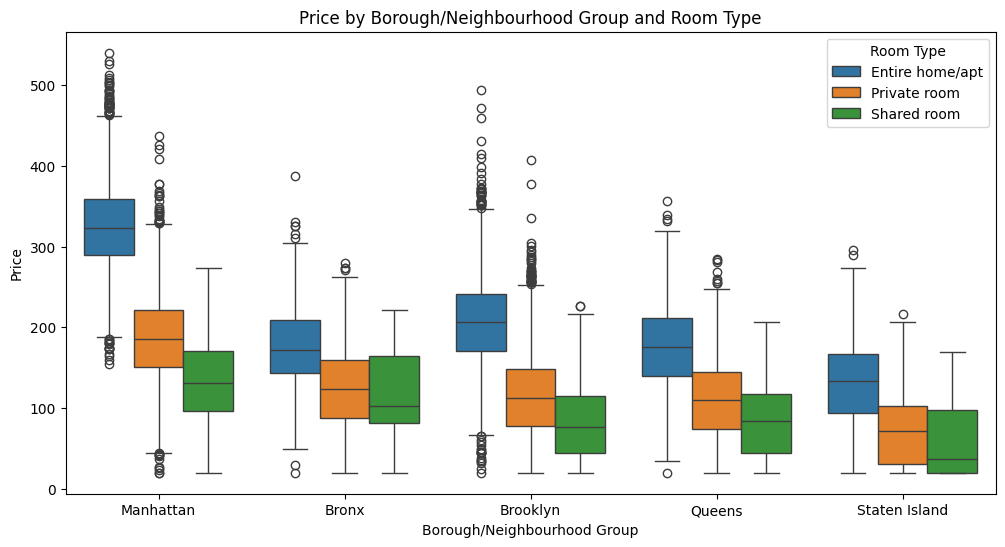

In [92]:
# price + room_type + neighbourhood_group Comparison
plt.figure(figsize = (12, 6))
sns.boxplot(
    data = air_bnb,
    x = "neighbourhood_group",
    y = "price",
    hue = "room_type"
)

plt.title("Price by Borough/Neighbourhood Group and Room Type")
plt.xlabel("Borough/Neighbourhood Group")
plt.ylabel("Price")
plt.legend(title = "Room Type")
plt.show()

In [93]:
air_bnb.groupby([
    "neighbourhood_group",
    "room_type"
    ]) ["price"].describe()

count        mean        std    min  \
neighbourhood_group room_type                                               
Bronx               Entire home/apt   606.0  175.409241  51.444209   20.0   
                    Private room      579.0  125.082902  49.981658   20.0   
                    Shared room        23.0  120.130435  57.905334   20.0   
Brooklyn            Entire home/apt  6451.0  206.341652  52.259731   20.0   
                    Private room     5605.0  113.806601  51.404011   20.0   
                    Shared room       252.0   84.464286  49.913498   20.0   
Manhattan           Entire home/apt  6808.0  325.263073  52.607522  155.0   
                    Private room     6143.0  187.036627  52.388445   20.0   
                    Shared room       282.0  132.748227  50.921862   20.0   
Queens              Entire home/apt  1417.0  175.987297  52.326157   20.0   
                    Private room     1189.0  110.725820  51.002415   20.0   
                    Shared room        53.0   84.226415  52.779527   20.0   
Staten Island       Entire home/apt   302.0  132.245033  52.458681   20.0   
                    Private room      274.0   75.105839  45.566517   20.0   
                    Shared room        16.0   60.875000  51.266461   20.0   

                                       25%    50%     75%    max  
neighbourhood_group room_type                                     
Bronx               Entire home/apt  143.0  172.5  209.00  387.0  
                    Private room      88.0  124.0  159.50  280.0  
                    Shared room       82.0  102.0  165.00  221.0  
Brooklyn            Entire home/apt  171.0  206.0  241.00  494.0  
                    Private room      78.0  113.0  148.00  407.0  
                    Shared room       44.0   77.0  115.00  227.0  
Manhattan           Entire home/apt  290.0  323.0  359.00  540.0  
                    Private room     151.0  186.0  222.00  437.0  
                    Shared room       96.0  130.5  171.00  274.0  
Queens              Entire home/apt  140.0  176.0  212.00  356.0  
                    Private room      74.0  110.0  145.00  285.0  
                    Shared room       45.0   84.0  118.00  207.0  
Staten Island       Entire home/apt   94.0  133.0  167.00  296.0  
                    Private room      30.5   71.5  103.00  217.0  
                    Shared room       20.0   36.5   97.75  170.0

# **2. *Latitude* + *Longitude* + *Price* Analysis**

Here, we analyze **latitude, longitude, and price together** to examine how rental prices are geographically distributed across different locations.

## Observations

- `latitude` and `longitude` represent the geographical location of each listing, while `price` represents its rental price.

- By plotting the geographical coordinates and representing price using different point values, we can identify **spatial patterns in rental prices**.

- Listings located in different geographical areas show noticeable differences in price, indicating that **location is an important factor affecting rental prices**.

- Higher-priced listings are concentrated in particular geographical areas, while lower-priced listings are more widely distributed across other locations.

- The combination of latitude and longitude provides a more detailed geographical view than analysing neighbourhood groups alone because it shows the **actual spatial distribution of individual listings**.

## Conclusion

Overall, the analysis shows that **rental prices vary geographically**. The combination of latitude, longitude, and price helps identify areas where listings tend to have higher or lower prices and demonstrates the influence of **location on rental pricing**.

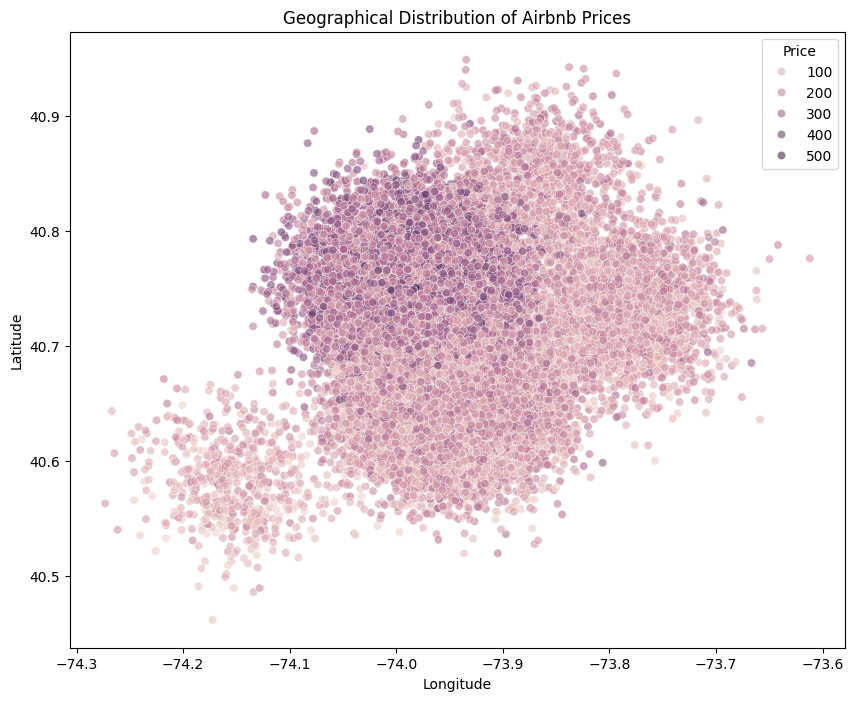

In [94]:
# price + latitude + longitude Comparison
plt.figure(figsize = (10, 8))
sns.scatterplot(
    data = air_bnb,
    x = "longitude",
    y = "latitude",
    hue = "price",
    alpha = 0.6
)

plt.title("Geographical Distribution of Airbnb Prices")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title = "Price")
plt.show()

# **3. *Reviews* + *Availability* + *Price* Analysis**

Here, we analyze the relationship between **number of reviews**, **availability throughout the year**, and **rental price** to determine whether these factors are related to each other.

## Observations

- The dataset contains **30,000 listings**. The average number of reviews is **34.97**, while the average availability is **182.13 days** and the average rental price is **200.65**.

- The number of reviews ranges from **12 to 64**, while `availability_365` ranges from **0 to 363 days**. Rental prices range from **20.00 to 540.00**.

- The relationship between **number of reviews and price** does not show a strong or consistent pattern. Rental prices remain relatively close to the overall average across different review-count levels.

- Similarly, **availability and price** do not show a clear increasing or decreasing pattern. Listings with higher availability can have both relatively low and high prices.

- Therefore, having more reviews does not necessarily mean that a listing has a higher price. Likewise, being available for more days throughout the year does not necessarily result in a higher or lower rental price.

- The three variables show considerable variation, indicating that **reviews and availability alone are not sufficient to explain differences in rental price**.

## Conclusion

Overall, the analysis suggests that **number of reviews and availability have relatively weak and inconsistent relationships with rental price** in this dataset. Other factors, particularly **room type and neighbourhood**, appear to be more important when explaining variations in Airbnb rental prices.

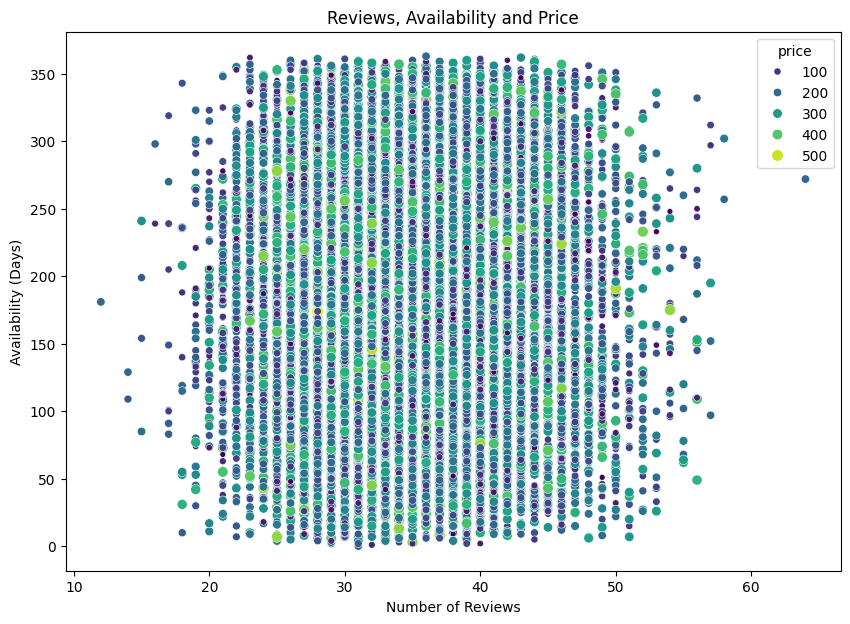

In [95]:
# number_of_reviews + availability_365 + price Comparison
plt.figure(figsize = (10, 7))

sns.scatterplot(
    data = air_bnb,
    x = "number_of_reviews",
    y = "availability_365",
    hue = "price",
    size = "price",
    palette = "viridis",
)

plt.title("Reviews, Availability and Price")
plt.xlabel("Number of Reviews")
plt.ylabel("Availability (Days)")
plt.show()

# **4. Correlation Heatmap Analysis of Numeric Variables**

Here, we analyze the **correlation heatmap of numeric variables** to understand the linear relationships between the different numerical features in the dataset.

## Observations

- The correlation matrix includes variables such as `price`, `minimum_nights`, `number_of_reviews`, `reviews_per_month`, `calculated_host_listings_count`, `availability_365`, `latitude`, and `longitude`.

- **Price Correlations:**
  - `price` has a moderate positive correlation with `latitude` (**0.36**). This reflects the geographic influence on pricing, where listings further north (such as Manhattan) tend to command higher prices.
  - `price` exhibits a weak negative correlation with `longitude` (**-0.20**).
  - `price` shows virtually **no linear correlation** with `minimum_nights` (**-0.00**), `number_of_reviews` (**0.00**), `reviews_per_month` (**-0.01**), `calculated_host_listings_count` (**0.01**), or `availability_365` (**-0.00**).

- **Inter-variable Correlations:**
  - Most other numerical feature pairs show correlation coefficients close to **0.00**, indicating a lack of linear association between them. For instance, `minimum_nights`, `number_of_reviews`, `reviews_per_month`, `calculated_host_listings_count`, and `availability_365` are largely independent of one another in linear terms.
  - A minor positive correlation of **0.09** exists between `latitude` and `longitude`, which naturally represents the geographic coordinate layout of the region.

- Overall, the correlation heatmap indicates that **traditional numerical features (like reviews, stay requirements, and availability) do not have strong linear relationships with price**. The most notable linear relationship with price is spatial, captured through geographical coordinates (`latitude` and `longitude`).

## Conclusion

The correlation analysis demonstrates that **geographic location (represented by latitude)** has the most notable linear association with rental price, while other numeric operational variables display minimal linear correlation with pricing.

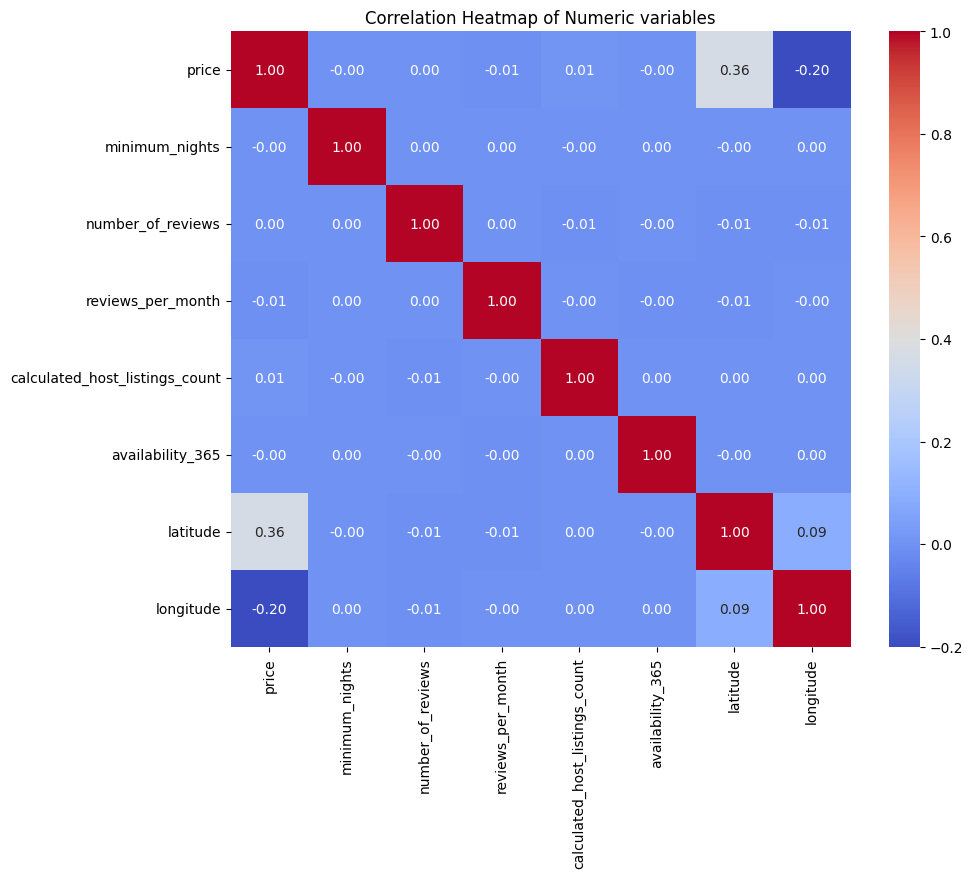

In [96]:
numeric_columns = [
    'price',
    'minimum_nights',
    'number_of_reviews',
    'reviews_per_month',
    'calculated_host_listings_count',
    'availability_365',
    'latitude',
    'longitude'
]

plt.figure(figsize = (10, 8))
sns.heatmap(
    air_bnb[numeric_columns].corr(),
    annot = True,
    cmap = "coolwarm",
    fmt = ".2f"
)

plt.title("Correlation Heatmap of Numeric variables")
plt.show()

# **Feature Engineering**

In [97]:
# Create features from last_review
air_bnb["last_review_year"] = air_bnb["last_review"].dt.year
air_bnb["last_review_month"] = air_bnb["last_review"].dt.month


# Features used for prediction
basic_features = [
    "neighbourhood_group",
    "neighbourhood",
    "latitude",
    "longitude",
    "room_type",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "availability_365",
    "calculated_host_listings_count",
    "last_review_year",
    "last_review_month"
]


# Independent variables
X_basic = air_bnb[basic_features]

# Target variable
y = air_bnb["price"].copy()


print("X:", X_basic.shape)
print("Y:", y.shape)

X: (30000, 12)
Y: (30000,)


In [98]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_basic,
    y,
    test_size = 0.2,
    random_state = 42
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (24000, 12)
Testing: (6000, 12)


In [99]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_preprocessor = Pipeline(steps = [
    ("imputer", SimpleImputer(strategy = "median")),
    ("scaler", StandardScaler())
])

print("Numerical processing pipeline created.")

Numerical processing pipeline created.


In [101]:
from sklearn.preprocessing import OneHotEncoder

categorical_preprocessor = Pipeline(steps = [
    ("imputer", SimpleImputer(strategy = "most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown = "ignore",
        min_frequency = 5
        ))
])

print("Categorical processing pipeline created.")

Categorical processing pipeline created.


In [102]:
from sklearn.compose import ColumnTransformer

numerical_features = [
    "latitude",
    "longitude",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "availability_365",
    "calculated_host_listings_count",
    "last_review_year",
    "last_review_month"
]

categorical_features = [
    "neighbourhood_group",
    "neighbourhood",
    "room_type"
]

combined_preprocessor = ColumnTransformer(
    transformers = [
    ("numeric", numeric_preprocessor, numerical_features),
    ("tcatergorical", categorical_preprocessor, categorical_features)
    ],
    remainder = "drop"
)

print("Combined numerical + categorical preprocessor created.")

Combined numerical + categorical preprocessor created.


In [113]:
# Linear Regression
linear_regression = Pipeline([
    ("preprocessing", combined_preprocessor),
    ("model", LinearRegression())
])

print("Baseline Linear Regression trained")

Baseline Linear Regression trained


In [114]:
# Random Forest
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

random_forest = Pipeline([
    ("preprocessing", combined_preprocessor),
    ("model", RandomForestRegressor(
        n_estimators = 100,
        random_state = 42,
        n_jobs = -1
    ))
])

print("Random Forest Regression trained")

Random Forest Regression trained


In [117]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
import time

def evaluate_regression(model_name, model, X_train, X_test, y_train, y_test):
  start = time.time()
  model.fit(X_train, y_train)
  predictions = model.predict(X_test)

  result = {
      "model" : model_name,
      "MAE" : mean_absolute_error(y_test, predictions),
      "RMSE" : mean_squared_error(y_test, predictions) ** 0.5,
      "R2" : r2_score(y_test, predictions),
      "training_seconds" : time.time() - start
  }

  return result, predictions

display(evaluate_regression("Linear Regression", linear_regression, X_train, X_test, y_train, y_test))
display(evaluate_regression("Random Forest", random_forest, X_train, X_test, y_train, y_test))

({'model': 'Linear Regression',
  'MAE': 42.53681273057864,
  'RMSE': 53.730869263992076,
  'R2': 0.662157304710336,
  'training_seconds': 0.22037053108215332},
 array([312.85658978, 306.24112071, 204.29257967, ..., 205.58873131,
        102.54294499, 218.9230666 ]))

({'model': 'Random Forest',
  'MAE': 42.12897666666667,
  'RMSE': 52.97395674574441,
  'R2': 0.6716087135472175,
  'training_seconds': 185.26841974258423},
 array([319.47, 324.73, 170.27, ..., 183.33, 101.66, 228.03]))